# Supplementary Figure 3: sensitivity to PCN-dynamics transition increments

In [1]:
%matplotlib inline
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.environ.setdefault("SIM_RUN_MODE", "production")
%run ./simulation_core.ipynb

OUTPUT_ROOT, FIGURE_DIR, SOURCE_DIR = make_output_dirs("Supplementary_Figure_3_outputs")
SETTINGS={
    "reduced": dict(kf=0.175,kb=0.170),
    "primary": dict(kf=TRANSITIONS.kappa_f_pcn,kb=TRANSITIONS.kappa_b_pcn),
}
SCENARIOS=[("a",100,"reduced"),("b",100,"primary"),("c",50,"reduced"),("d",50,"primary"),("e",20,"reduced"),("f",20,"primary")]

def configs_for(max_pcn,setting):
    s=SETTINGS[setting]
    return [
      make_configuration(max_pcn,condition="transposition off",kappa_f=TRANSITIONS.kappa_f_off,kappa_b=TRANSITIONS.kappa_b_off,setting_label=setting),
      make_configuration(max_pcn,condition="transposition on",kappa_f=TRANSITIONS.kappa_f_on,kappa_b=TRANSITIONS.kappa_b_on,setting_label=setting),
      make_configuration(max_pcn,condition="transposition on + PCN dynamics",kappa_f=s["kf"],kappa_b=s["kb"],setting_label=setting),
    ]


In [2]:
fixed={}; transient={}; cycle_tables=[]
for panel,max_pcn,setting in SCENARIOS:
    for config in configs_for(max_pcn,setting):
        for phase,duration,init in (("loss",RELAXED_DAYS_PER_CYCLE,fixed_loss_initial_state(max_pcn)),
                                    ("gain",SELECTED_DAYS_PER_CYCLE,fixed_gain_initial_state(max_pcn))):
            t,_,_,_=simulate_phase(max_pcn,config,phase=phase,duration_days=duration,initial_state=init,record_trajectory=True)
            fixed[(panel,phase,config.condition)]=t
        t,_,ct=simulate_transient_cycles(max_pcn,config,cycles=TRANSIENT_CYCLES)
        transient[(panel,config.condition)]=t; ct["panel"]=panel; cycle_tables.append(ct)

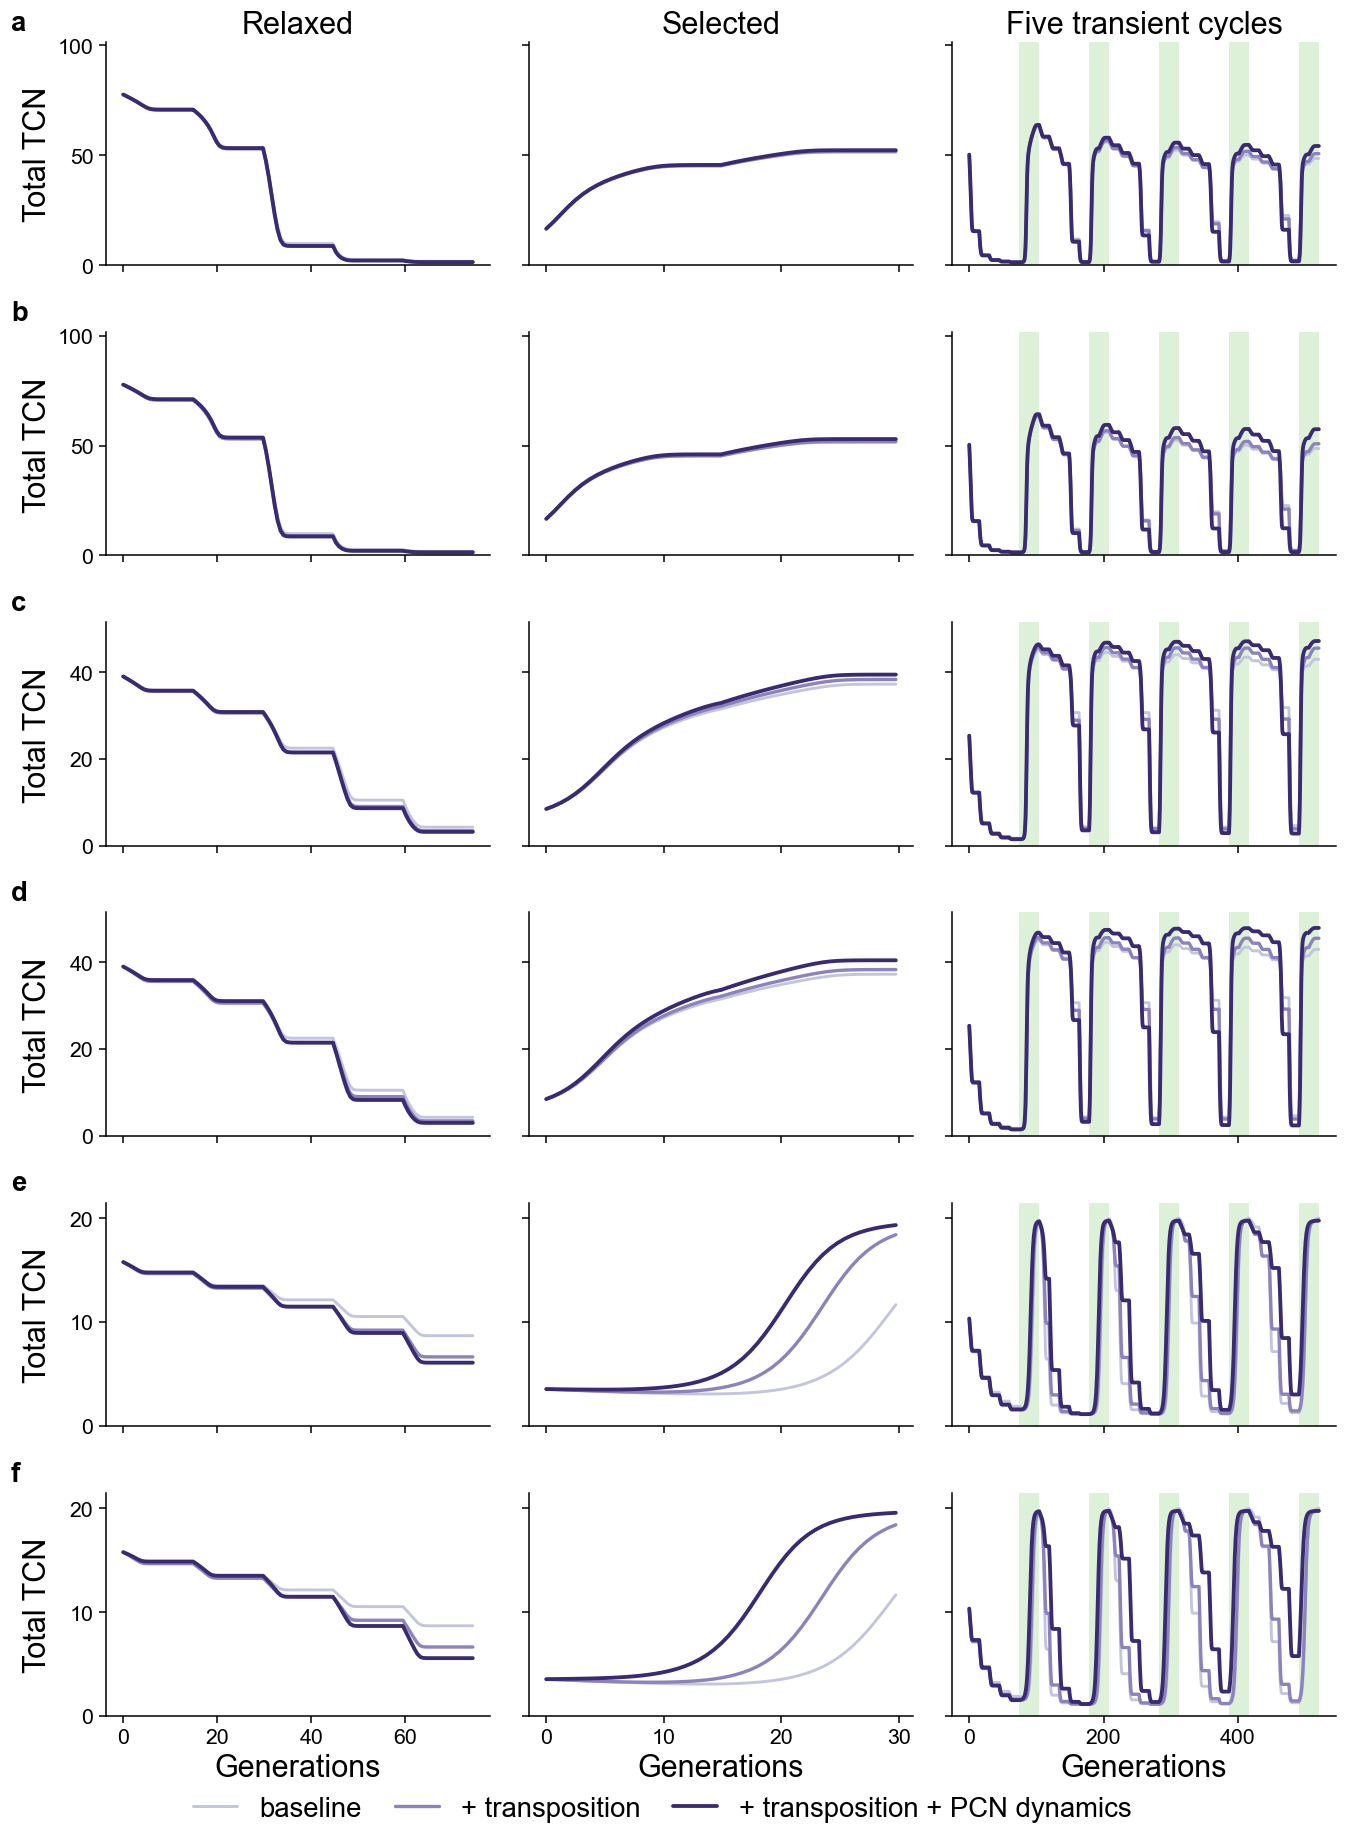

In [3]:
plt.rcParams.update(PLOT_STYLE)
LARGE_FONT_STYLE = {
    "font.size": 14, "axes.labelsize": 20, "axes.titlesize": 20,
    "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 18,
    "axes.linewidth": 1.0, "xtick.major.width": 1.0, "ytick.major.width": 1.0,
    "xtick.major.size": 4.5, "ytick.major.size": 4.5,
}
plt.rcParams.update(LARGE_FONT_STYLE)
PANEL_FONT = 18
fig=plt.figure(figsize=(12.5,17.0))
gs=fig.add_gridspec(6,3,left=0.095,right=0.99,bottom=0.07,top=0.965,wspace=0.10,hspace=0.30)
axes=np.empty((6,3),dtype=object)
for r in range(6):
    for j in range(3):
        axes[r,j]=fig.add_subplot(gs[r,j],sharex=axes[0,j] if r else None,sharey=axes[r,0] if j else None)
for j,title in enumerate(("Relaxed","Selected","Five transient cycles")): axes[0,j].set_title(title)
for r,(panel,max_pcn,setting) in enumerate(SCENARIOS):
    cfgs=configs_for(max_pcn,setting)
    for j,phase in enumerate(("loss","gain")):
        for c in cfgs:
            d=fixed[(panel,phase,c.condition)]
            axes[r,j].plot(d.phase_day*PASSAGE_GENERATIONS,d.TCN_per_density,color=CONDITION_COLORS[c.condition],lw=CONDITION_LINEWIDTHS[c.condition]+0.8)
        axes[r,j].set_ylim(0,max_pcn+1.5)
        if j==0: axes[r,j].set_ylabel("Total TCN")
    for cyc in range(1,TRANSIENT_CYCLES+1):
        start=(cyc-1)*DAYS_PER_CYCLE+RELAXED_DAYS_PER_CYCLE
        axes[r,2].axvspan(start*PASSAGE_GENERATIONS,(start+SELECTED_DAYS_PER_CYCLE)*PASSAGE_GENERATIONS,color=SELECTION_SHADE,lw=0)
    for c in cfgs:
        d=transient[(panel,c.condition)]
        axes[r,2].plot(d.Day*PASSAGE_GENERATIONS,d.TCN_per_density,color=CONDITION_COLORS[c.condition],lw=CONDITION_LINEWIDTHS[c.condition]+0.8,label=DISPLAY_LABELS[c.condition])
    axes[r,2].set_ylim(0,max_pcn+1.5)
    for j in range(3):
        axes[r,j].locator_params(axis="y",nbins=4)
        if r==5: axes[r,j].set_xlabel("Generations")
        else: axes[r,j].tick_params(axis="x",labelbottom=False)
        if j: axes[r,j].tick_params(axis="y",labelleft=False)
    axes[r,0].annotate(panel,xy=(0,1),xycoords="axes fraction",xytext=(-62,4),textcoords="offset points",
                       fontsize=PANEL_FONT,fontweight="bold",va="bottom",ha="left")
fig.align_ylabels(axes[:,0])
handles,labels=axes[0,2].get_legend_handles_labels()
fig.legend(handles,labels,loc="lower center",bbox_to_anchor=(0.5,0.0),ncol=3,frameon=False,
           handlelength=1.6,columnspacing=1.2)
save_figure(fig,"Supplementary_Figure_3_pcn_dynamics_sensitivity",FIGURE_DIR); plt.show()

source=[]
for (panel,phase,condition),d in fixed.items():
    x=d.copy(); x["panel"]=panel; x["analysis"]="fixed"; source.append(x)
for (panel,condition),d in transient.items():
    x=d.copy(); x["panel"]=panel; x["analysis"]="transient"; source.append(x)
export_table(pd.concat(source,ignore_index=True),"Supplementary_Figure_3_source_data.csv",SOURCE_DIR)
export_table(pd.concat(cycle_tables,ignore_index=True),"Supplementary_Figure_3_cycle_endpoints.csv",SOURCE_DIR)
export_table(core_metadata("Supplementary Figure 3"),"Supplementary_Figure_3_run_metadata.csv",SOURCE_DIR)
